# Ensemble of three five-fold members and one fold-0 member

Notebook 20 averaged two five-fold members (Exp3 and Exp5, notebooks `cv/03` and `cv/04`) and two fold-0 members (Exp1 and Exp7). It scored 0.98367 on the public leaderboard, our best so far. Exp1 (ConvNeXt-base) now has a five-fold version too (notebook `cv/01`): its test probabilities are the mean of five fold models, each trained on a different 80% of the data. This notebook replaces only that member and keeps the method of notebooks 18 and 20: equal weights and the fixed threshold 0.25. So any change in the score comes from the five-fold ConvNeXt, not from weights or thresholds. Exp7 (HRNet-W32) is still a fold-0 model.

The notebook only reads saved probabilities. No model is run. The submission CSV and its record are written only with `BUILD_SUBMISSION=True`, and never over an existing file. Kaggle upload is always manual.

In [1]:
from __future__ import annotations

import json
import os
import subprocess
import sys
from pathlib import Path

import numpy as np

BUILD_SUBMISSION = True
SUBMIT_TO_KAGGLE = False  # No submission API call exists in this notebook.

RUN_ID = 'cv_ensemble_cvexp1_cvexp3_cvexp5_exp7_mean_025'
THRESHOLD = 0.25
VALIDATION_FOLD = 0
# Member -> its fold-0 run (old member) or its five-fold folder under experiments/cv/ (new members).
FOLD0_MEMBERS = {
    'exp07': ('exp07', 'hrnet_w32_finetune_fold0_seed42'),
}
CV_MEMBERS = {'cv_exp1': 'convnext', 'cv_exp3': 'efficientnetv2s', 'cv_exp5': 'bit_r50x1'}
# Earlier submissions to compare with, cell by cell.
EARLIER = {
    'notebook 20, two five-fold (public 0.98367)': 'submissions/cv_ensemble_exp1_cvexp3_cvexp5_exp7_mean_025.csv',
    'old 4-mean (public 0.97816)': 'submissions/exp4_ensemble_exp1_exp3_exp5_exp7_mean_025.csv',
    'best, skill weights (public 0.98305)': 'submissions/exp4_weighted_skill_exp1_exp3_exp5_exp7_025.csv',
}

start = Path(os.environ.get('STAGE2_ROOT', Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents) if (path / 'folds.csv').is_file() and (path / 'stage2' / 'cv.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Launch Jupyter from this repository or a subdirectory, or set STAGE2_ROOT.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

## Load the members

The old member (Exp7) gives its fold-0 validation probabilities and its saved test probabilities (the same files as in notebook 18). The five-fold members give their validation probabilities for all training images, the fold of each image, and their fold-mean test probabilities; `read_cv_summary` checks each file against the hash in `cv.json`. All four members must use the same fold file and label order. Every file is aligned to the image IDs of `data/train.csv` and `data/test.csv`, so the rows match across members.

In [2]:
from stage2.cv import read_cv_summary, sha256
from stage2.ensemble import mean_probabilities, read_probabilities
from stage2.experiment import LABEL_COLUMNS, form_submission, read_csv, score_probabilities, write_run_record, write_submission

DATA_DIR = ROOT / 'data'
train_rows = read_csv(DATA_DIR / 'train.csv', ('image_id', *LABEL_COLUMNS))
train_ids = [row['image_id'] for row in train_rows]
train_targets = np.asarray([[int(row[label]) for label in LABEL_COLUMNS] for row in train_rows])
test_ids = [row['image_id'] for row in read_csv(DATA_DIR / 'test.csv', ('image_id',))]
fold_sha256 = sha256(ROOT / 'folds.csv')

cv_members = {name: read_cv_summary(ROOT / 'experiments' / 'cv' / folder, train_ids, test_ids) for name, folder in CV_MEMBERS.items()}
folds = cv_members['cv_exp3']['folds']
for name, member in cv_members.items():
    data = member['record']['data']
    if data['fold_sha256'] != fold_sha256 or data['label_columns'] != list(LABEL_COLUMNS):
        raise ValueError(f'{name} used another fold file or label order.')
    if not np.array_equal(member['folds'], folds):
        raise ValueError(f'{name} assigns images to other folds.')
in_fold0 = folds == VALIDATION_FOLD
validation_ids = [image_id for image_id, is_fold0 in zip(train_ids, in_fold0) if is_fold0]
validation_targets = train_targets[in_fold0]

validation_probabilities, test_probabilities, member_sources = {}, {}, {}
for name, (experiment, run_id) in FOLD0_MEMBERS.items():
    run_dir = ROOT / 'experiments' / experiment / 'results' / run_id
    record = json.loads((run_dir / f'{run_id}.json').read_text())
    if record['fold'] != VALIDATION_FOLD or record['data']['fold_sha256'] != fold_sha256 or record['data']['label_columns'] != list(LABEL_COLUMNS):
        raise ValueError(f'{run_id} is not a fold-0 run on the same folds and labels.')
    validation_probabilities[name] = read_probabilities(run_dir / f'{run_id}_val.csv', validation_ids)
    test_csv = ROOT / 'experiments' / experiment / 'results' / f'{run_id}_test' / f'{run_id}_test.csv'
    test_probabilities[name] = read_probabilities(test_csv, test_ids)
    member_sources[name] = {'kind': 'fold-0 model', 'run_id': run_id, 'test_csv_sha256': sha256(test_csv)}
for name, member in cv_members.items():
    validation_probabilities[name] = member['oof'][in_fold0]
    test_probabilities[name] = member['test']
    member_sources[name] = {'kind': 'five-fold mean', 'folder': f'experiments/cv/{CV_MEMBERS[name]}', 'cv_record_sha256': sha256(ROOT / 'experiments' / 'cv' / CV_MEMBERS[name] / 'cv.json'),
                            'fold_sources': member['record']['fold_sources']}
MEMBERS = list(validation_probabilities)
print('Members:', MEMBERS, f'| fold-0 images: {len(validation_ids)} | test images: {len(test_ids)}')
for name in CV_MEMBERS:
    print(name, 'fold sources:', cv_members[name]['record']['fold_sources'])

Members: ['exp07', 'cv_exp1', 'cv_exp3', 'cv_exp5'] | fold-0 images: 2452 | test images: 18673
cv_exp1 fold sources: {'0': 'imported', '1': 'trained', '2': 'trained', '3': 'trained', '4': 'trained'}
cv_exp3 fold sources: {'0': 'imported', '1': 'trained', '2': 'trained', '3': 'trained', '4': 'trained'}
cv_exp5 fold sources: {'0': 'imported', '1': 'trained', '2': 'trained', '3': 'trained', '4': 'trained'}


## Sanity check on fold 0

Fold 0 is the only fold with predictions from all four members. The fold-0 model of each five-fold member is the old fold-0 run, imported unchanged (see the fold sources above). So the four fold-0 predictions are the same as in notebooks 18 and 20, and the mean must again score 0.99832. This checks that the files load and align. It cannot rank the ensembles: notebook 18 showed that fold 0 points the wrong way for this question.

In [3]:
candidates = {**validation_probabilities, 'mean': mean_probabilities([validation_probabilities[name] for name in MEMBERS])}
print(f"{'model':<8} {'F1@0.25':>8} " + ' '.join(f'{label:>8}' for label in LABEL_COLUMNS))
for name, probabilities in candidates.items():
    metrics = score_probabilities(validation_targets, probabilities, THRESHOLD)
    print(f"{name:<8} {metrics['macro_f1']:>8.5f} " + ' '.join(f"{metrics['per_label_f1'][label]:>8.4f}" for label in LABEL_COLUMNS))

model     F1@0.25      Cat      Dog    Moris    Motya  Biatrix
exp07     0.99733   0.9941   0.9925   1.0000   1.0000   1.0000
cv_exp1   0.97518   0.9966   0.9970   1.0000   0.9412   0.9412
cv_exp3   0.99831   0.9971   0.9945   1.0000   1.0000   1.0000
cv_exp5   0.99851   0.9970   0.9955   1.0000   1.0000   1.0000
mean      0.99832   0.9956   0.9960   1.0000   1.0000   1.0000


## What changes on the test set

Here the members differ from notebook 20: Exp1 now predicts the test set with the mean of five fold models, like Exp3 and Exp5. We count the test cells (image, label) where the new ensemble differs from notebook 20, from the old four-model mean and from the `skill`-weighted submission. One named-pet cell is worth about 0.0007 public macro F1, and a Cat or Dog cell about 0.00001 (notebook 19), so the named-pet columns matter most. The second table shows how many members vote for each named-pet positive.

In [4]:
named_pets = [LABEL_COLUMNS.index(label) for label in ('Moris', 'Motya', 'Biatrix')]
ensemble_test = mean_probabilities([test_probabilities[name] for name in MEMBERS])
decided = ensemble_test >= THRESHOLD

compared = {'this notebook': decided}
for title, path in EARLIER.items():
    rows = {row['image_id']: row for row in read_csv(ROOT / path, ('image_id', *LABEL_COLUMNS))}
    compared[title] = np.asarray([[int(rows[image_id][label]) for label in LABEL_COLUMNS] for image_id in test_ids], dtype=bool)

print(f"{'test positives':<38}" + ''.join(f'{label:>8}' for label in LABEL_COLUMNS))
for title, labels in compared.items():
    print(f'{title:<38}' + ''.join(f'{int(labels[:, index].sum()):>8}' for index in range(len(LABEL_COLUMNS))))
print('\nCells where this notebook differs (added/removed positives):')
for title in EARLIER:
    added, removed = decided & ~compared[title], ~decided & compared[title]
    print(f'  vs {title:<37} ' + ''.join(f'{label} +{int(added[:, i].sum())}/-{int(removed[:, i].sum())}  ' for i, label in enumerate(LABEL_COLUMNS)))

votes = np.sum([test_probabilities[name][:, named_pets] >= THRESHOLD for name in MEMBERS], axis=0)
print('\nNamed-pet positives by the number of members that vote for them:')
for position, label_index in enumerate(named_pets):
    positive = decided[:, label_index]
    print(f'  {LABEL_COLUMNS[label_index]:<8} {int(positive.sum()):>4}: ' + ', '.join(f'{count} members {int((positive & (votes[:, position] == count)).sum())}' for count in range(1, len(MEMBERS) + 1)))

test positives                             Cat     Dog   Moris   Motya Biatrix
this notebook                             7815    7710     175     140     183
notebook 20, two five-fold (public 0.98367)    7817    7711     173     139     183
old 4-mean (public 0.97816)               7825    7700     165     138     184
best, skill weights (public 0.98305)      7826    7701     170     135     185

Cells where this notebook differs (added/removed positives):
  vs notebook 20, two five-fold (public 0.98367) Cat +0/-2  Dog +3/-4  Moris +2/-0  Motya +1/-0  Biatrix +1/-1  
  vs old 4-mean (public 0.97816)           Cat +10/-20  Dog +26/-16  Moris +10/-0  Motya +4/-2  Biatrix +2/-3  
  vs best, skill weights (public 0.98305)  Cat +8/-19  Dog +24/-15  Moris +6/-1  Motya +5/-0  Biatrix +0/-2  

Named-pet positives by the number of members that vote for them:
  Moris     175: 1 members 2, 2 members 10, 3 members 17, 4 members 146
  Motya     140: 1 members 2, 2 members 7, 3 members 10, 4 member

## Test images where notebooks 20 and 21 disagree

Only 14 test cells differ between the two submissions, so we can look at the photos. Each title lists the labels that changed (notebook 20 → notebook 21) and, for those labels, the probability from the old fold-0 Exp1 (the member notebook 20 used), the new five-fold Exp1 and the ensemble mean. Images with a changed named-pet label (Moris, Motya, Biatrix) come first. Reading the photos is only a plausibility check: with this few images it cannot rank the two submissions, and the public score has the last word.

14 differing cells in 14 images; showing 8.


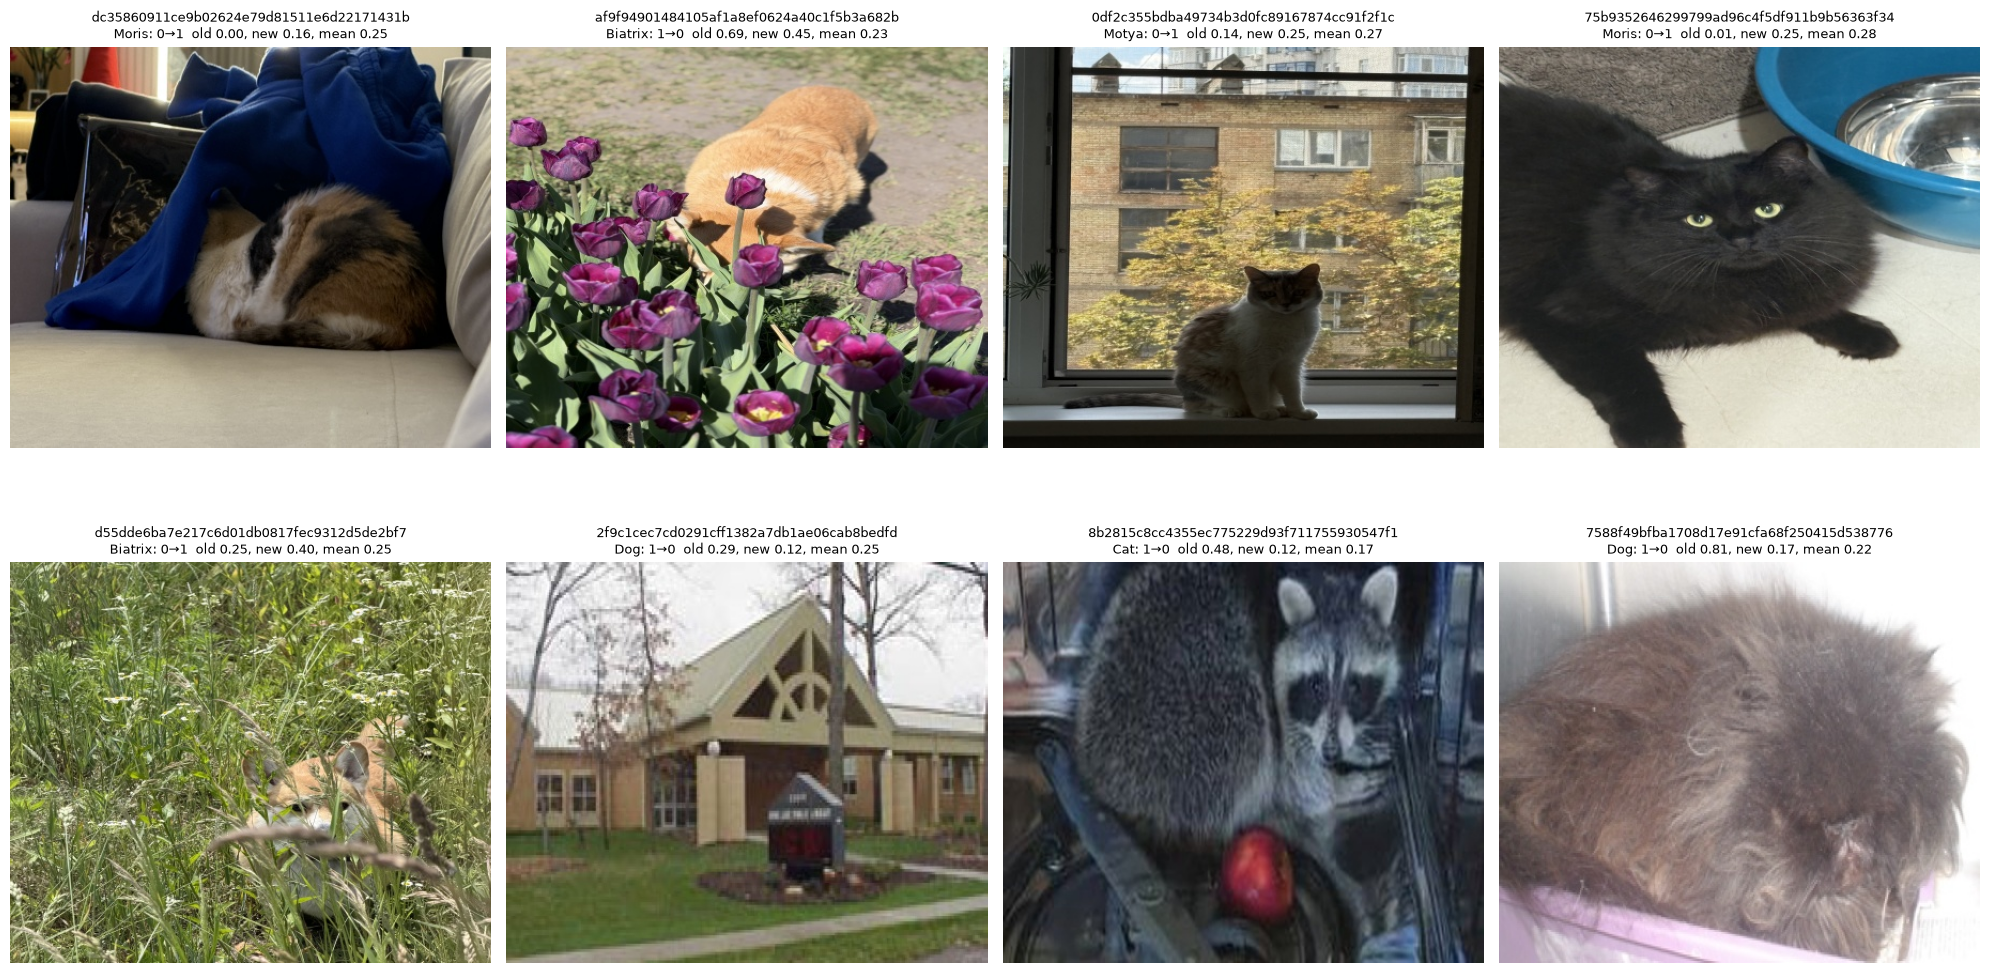

In [5]:
import matplotlib.pyplot as plt
from PIL import Image

OLD_EXP1 = ('exp1', 'convnext_standard_fold0_seed42_20261018_full1')  # The member notebook 20 used.
MAX_IMAGES = 8
old_test_csv = ROOT / 'experiments' / OLD_EXP1[0] / 'results' / f'{OLD_EXP1[1]}_test' / f'{OLD_EXP1[1]}_test.csv'
old_exp1 = read_probabilities(old_test_csv, test_ids)

previous = compared['notebook 20, two five-fold (public 0.98367)']
differs = decided != previous
rows = np.flatnonzero(differs.any(axis=1))
rows = sorted(rows, key=lambda row: (-int(differs[row, named_pets].sum()), -int(differs[row].sum()), row))
print(f'{int(differs.sum())} differing cells in {len(rows)} images; showing {min(len(rows), MAX_IMAGES)}.')

shown = rows[:MAX_IMAGES]
columns = 4
figure, axes = plt.subplots(-(-max(len(shown), 1) // columns), columns, figsize=(5 * columns, 5.6 * -(-max(len(shown), 1) // columns)), squeeze=False)
for axis in axes.ravel():
    axis.axis('off')
for axis, row in zip(axes.ravel(), shown):
    with Image.open(DATA_DIR / 'test' / f'{test_ids[row]}.jpg') as photo:
        axis.imshow(photo.convert('RGB'))
    lines = []
    for index in np.flatnonzero(differs[row]):
        lines.append(f'{LABEL_COLUMNS[index]}: {int(previous[row, index])}→{int(decided[row, index])}  '
                     f'old {old_exp1[row, index]:.2f}, new {test_probabilities["cv_exp1"][row, index]:.2f}, mean {ensemble_test[row, index]:.2f}')
    axis.set_title(f'{test_ids[row]}\n' + '\n'.join(lines), fontsize=9)
plt.tight_layout()
plt.show()

## Write the submission

The CSV goes to `submissions/` in sample-submission order. A record with the members and their file hashes goes to `experiments/cv/ensemble/<run-id>/`, next to the five-fold ensembles of notebook `cv/06` and the record of notebook 20. Nothing is overwritten. Upload by hand and write the public score into the record and the table below.

In [5]:
if BUILD_SUBMISSION:
    submission_path = ROOT / 'submissions' / f'{RUN_ID}.csv'
    record_path = ROOT / 'experiments' / 'cv' / 'ensemble' / RUN_ID / 'record.json'
    for path in (submission_path, record_path):
        if path.exists():
            raise FileExistsError(f'Refusing to overwrite {path}')
    git_commit = subprocess.run(['git', 'rev-parse', 'HEAD'], cwd=ROOT, capture_output=True, text=True).stdout.strip() or None
    write_submission(submission_path, form_submission(DATA_DIR / 'sample_submission.csv', test_ids, ensemble_test, THRESHOLD))
    write_run_record(record_path, {
        'run_id': RUN_ID, 'status': 'completed', 'method': 'equal-weight mean of member test probabilities, then fixed threshold',
        'threshold': THRESHOLD, 'members': member_sources,
        'data': {'fold_file': 'folds.csv', 'fold_sha256': fold_sha256, 'label_columns': list(LABEL_COLUMNS)},
        'submission_csv': str(submission_path.relative_to(ROOT)), 'submission_sha256': sha256(submission_path),
        'git_commit': git_commit, 'public_leaderboard_score': None,
    })
    print('CSV ready for manual upload:', submission_path.relative_to(ROOT))
    print('Record:', record_path.relative_to(ROOT))
else:
    print('No submission CSV built.')

FileExistsError: Refusing to overwrite /Users/allakovalcuk/AI301/deep-learning-assignment2/submissions/cv_ensemble_cvexp1_cvexp3_cvexp5_exp7_mean_025.csv

## Results and conclusions

_Public scores from the Kaggle submissions page. Notebook `cv/06` compares these submissions with the all-five-fold ensembles._

| Submission | Five-fold members | Public LB |
|---|---|---:|
| Mean of Exp1, Exp3, Exp5, Exp7 (notebook 18) | none | 0.97816 |
| Best weighted: `skill` weights (notebook 19) | none | 0.98305 |
| Mean of Exp1, Exp3, Exp5, Exp7 (notebook 20) | Exp3, Exp5 | 0.98367 |
| **Mean of Exp1, Exp3, Exp5, Exp7 (this notebook)** | Exp1, Exp3, Exp5 | **0.98374** |
| Mean of the four five-fold models (notebook `cv/06`, `eq4`) | Exp1, Exp3, Exp5, Exp7 | 0.97989 |


**This notebook and notebook 20 are tied (0.98374 against 0.98367, 0.1 named-pet cell).** Replacing the fold-0 ConvNeXt by its five-fold mean changed 5 named-pet cells and the score did not move. The ensemble with a five-fold HRNet instead of the fold-0 HRNet (`eq4`) scored 0.97989, 5.5 cells lower; see `cv/06` for why this is not evidence that the fold-0 HRNet is better.